In [1]:
%load_ext autoreload
%autoreload 2

In [19]:
import sys
from pathlib import Path

import numpy as np
from PIL import Image

cwd = Path.cwd()
PROJECT_ROOT = cwd.parent if cwd.name == "notebooks" else cwd
sys.path.insert(0, str(PROJECT_ROOT))

In [12]:
from weed_detector.config import load_config

config = load_config()

## 1. Preprocess data

In [5]:
from weed_detector.data.preprocess import create_data_splits

raw_data_dir = config["paths"]["raw_data_dir"]
processed_data_dir = config["paths"]["processed_data_dir"]

create_data_splits(raw_data_dir=raw_data_dir, processed_data_dir=processed_data_dir)

[INFO] Data splits already exist.


## 2. Training

### 2.1 Create YOLO data yaml

In [11]:
from weed_detector.utils.yolo import write_yolo_yaml

raw_dir = config["paths"]["raw_dir"]
processed_data_dir = config["paths"]["processed_data_dir"]
yolo_yaml_path = config["paths"]["yolo_yaml_path"]

write_yolo_yaml(raw_dir=raw_dir, processed_data_dir=processed_data_dir, yolo_yaml_path=yolo_yaml_path)

[INFO] YOLO data config written to '/home/adrian/projects/weed-detector/configs/yolo.yaml'


### 2.2 Train model

In [ ]:
from weed_detector.training.train import train

# Run training
metrics = train(
    config=config
    )

New https://pypi.org/project/ultralytics/8.4.177 available 😃 Update with 'pip install -U ultralytics'
Ultralytics 8.4.66 🚀 Python-3.12.13 torch-2.14.1+cu130 CPU (11th Gen Intel Core i7-1165G7 @ 2.80GHz)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/home/adrian/projects/weed-detector/configs/yolo.yaml, degrees=0.0, deterministic=True, device=cpu, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=2, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, half=False, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=512, int8=False, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=/home/adrian/projects/

## 3. Evaluation

In [17]:
from weed_detector.model.detector import load_model
from weed_detector.utils.paths import get_weights_path
from weed_detector.training.evaluate import eval


# Get path to trained model weights
weights_path = get_weights_path(
    config=config,
    cp="best"
    )

# Load model
model = load_model(
    weights_path=weights_path
)

# Eval on test set
metrics = eval(
    model=model,
    config=config
    )

Ultralytics 8.4.66 🚀 Python-3.12.13 torch-2.14.1+cu130 CPU (11th Gen Intel Core i7-1165G7 @ 2.80GHz)
Model summary (fused): 73 layers, 3,006,038 parameters, 0 gradients, 8.1 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 118.0±64.6 MB/s, size: 63.3 KB)
val: Scanning /home/adrian/projects/weed-detector/data/processed/labels/test... 195 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 195/195 584.0it/s 0.3s0.0s
val: New cache created: /home/adrian/projects/weed-detector/data/processed/labels/test.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 13/13 3.4s/it 44.0s2.6s
                   all        195        327      0.688      0.606      0.694      0.392
                  crop         93        199      0.647      0.525      0.647      0.407
                  weed        102        128       0.73      0.688      0.741      0.378
Speed: 1.9ms preprocess, 166.4ms inference, 0.0ms loss, 43.4ms postprocess per ima

## 4. Predict on single image

In [23]:
rnd_source_path

PosixPath('/home/adrian/projects/weed-detector/data/processed/images/test/agri_0_5953.jpeg')


image 1/1 /home/adrian/projects/weed-detector/data/processed/images/test/agri_0_5953.jpeg: 512x512 1 weed, 87.3ms
Speed: 2.0ms preprocess, 87.3ms inference, 1.2ms postprocess per image at shape (1, 3, 512, 512)


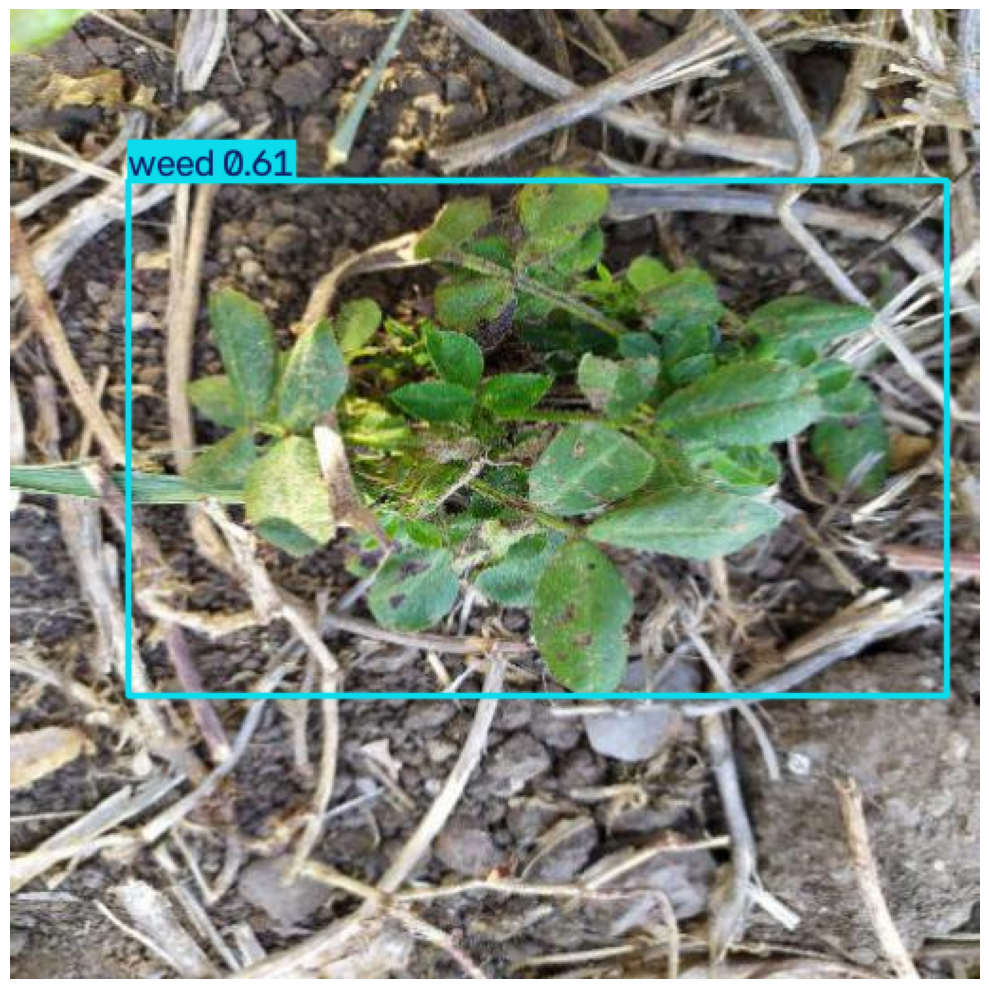

{'bbxs': array([[     62.437,      90.225,      494.53,      362.68]], dtype=float32), 'classes': array([          1], dtype=float32), 'class_names': ['weed'], 'scores': array([    0.61151], dtype=float32)}


In [22]:
%matplotlib inline
from weed_detector.inference.predict import predict
from weed_detector.model.detector import load_model

weights_path = PROJECT_ROOT / Path("models/trained/modelv2/train/weights/best.pt")
model = load_model(weights_path)

source_dir = PROJECT_ROOT /Path("data/processed/images/test")
rnd_source_path = np.random.choice(list(source_dir.iterdir()), 1)[0]

img = Image.open(rnd_source_path)

res = predict(model=model,
        config=config,
        image_path=rnd_source_path,
        conf_threshold=0.4)

print(res)

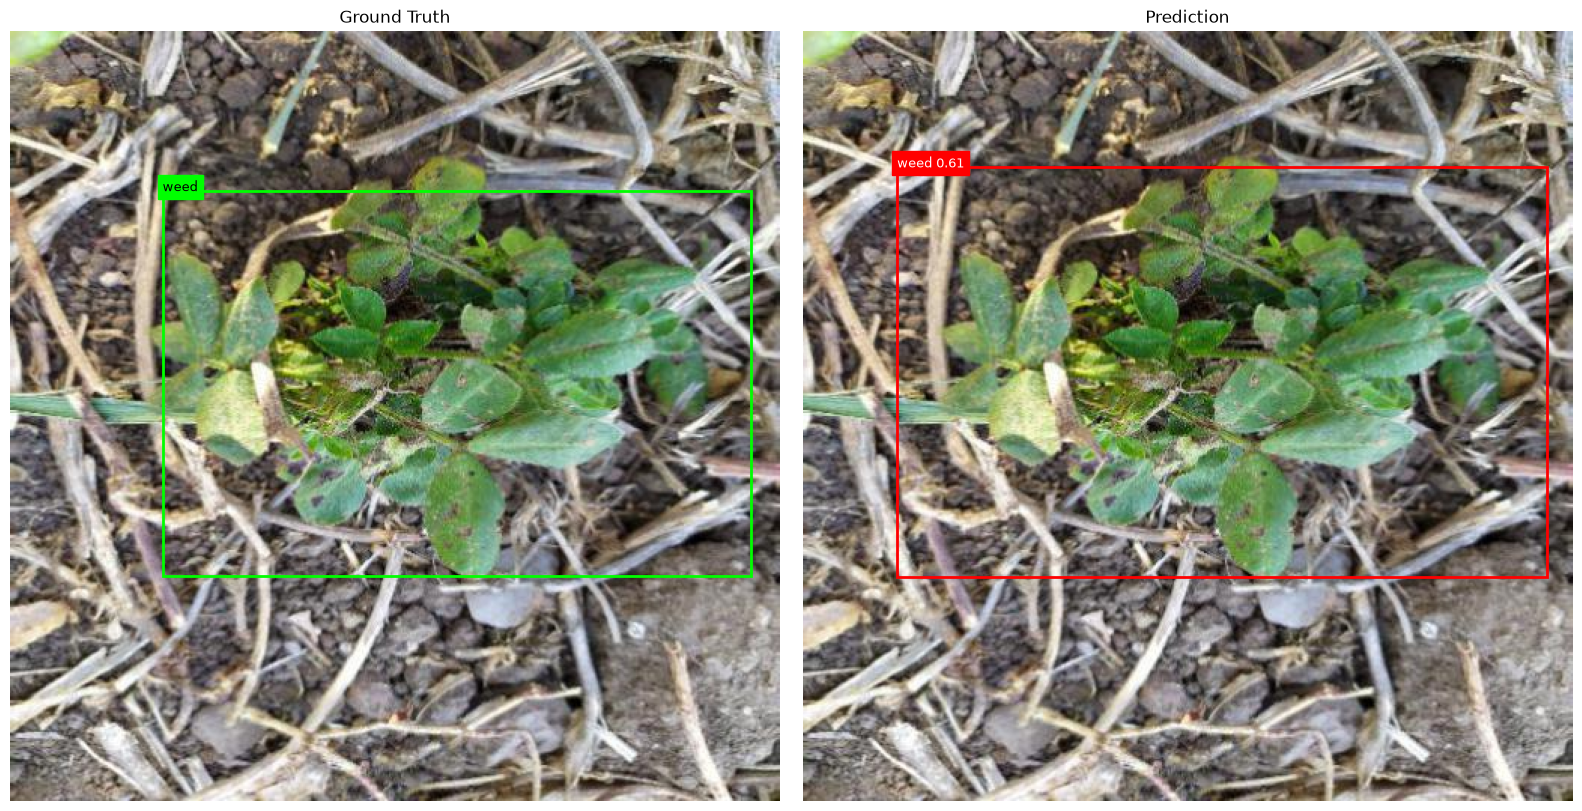

In [24]:

from pathlib import Path

import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from PIL import Image

from weed_detector.utils.labels import get_lbl_arrays


def plot_gt_vs_prediction(
    image_path: str | Path,
    res: dict,
    labels_dir: str | Path | None = None,
    idx_to_class: dict | None = None,
) -> None:
    """Plot ground-truth and predicted bounding boxes side by side."""

    image_path = Path(image_path)

    # Infer label path from .../images/test/name.jpeg
    if labels_dir is None:
        parts = list(image_path.parts)
        image_idx = parts.index("images")
        parts[image_idx] = "labels"
        label_path = Path(*parts).with_suffix(".txt")
    else:
        label_path = Path(labels_dir) / f"{image_path.stem}.txt"

    image = Image.open(image_path).convert("RGB")
    width, height = image.size

    # Ground truth: normalized YOLO format (class, x_center, y_center, w, h)
    gt_classes, gt_boxes = get_lbl_arrays(label_path)

    if idx_to_class is None:
        idx_to_class = {0: "crop", 1: "weed"}

    fig, axes = plt.subplots(1, 2, figsize=(16, 8))

    for ax, title in zip(axes, ["Ground Truth", "Prediction"]):
        ax.imshow(image)
        ax.set_title(title)
        ax.axis("off")

    # Plot GT boxes
    for cls, (xc, yc, w, h) in zip(gt_classes, gt_boxes):
        x, y = (xc - w / 2) * width, (yc - h / 2) * height
        w, h = w * width, h * height

        axes[0].add_patch(
            Rectangle((x, y), w, h, fill=False, edgecolor="lime", linewidth=2)
        )
        axes[0].text(
            x, y, idx_to_class.get(int(cls), str(cls)),
            color="black", backgroundcolor="lime", fontsize=9,
        )

    # Plot predicted boxes: xyxy pixel coordinates
    for box, cls, name, score in zip(
        res["bbxs"], res["classes"], res["class_names"], res["scores"]
    ):
        x1, y1, x2, y2 = box

        axes[1].add_patch(
            Rectangle(
                (x1, y1), x2 - x1, y2 - y1,
                fill=False, edgecolor="red", linewidth=2,
            )
        )
        axes[1].text(
            x1, y1, f"{name} {score:.2f}",
            color="white", backgroundcolor="red", fontsize=9,
        )

    plt.tight_layout()
    plt.show()

plot_gt_vs_prediction(rnd_source_path, res)